# 01 · Download and freeze the data

**Goal.** Know exactly what data we have, fix it at one date so results don't shift while we model, and download the last missing dataset (rivers and basins).

**Inputs.** The raw data already on `/data9`, and the GISTDA, CHIRPS and HydroSHEDS websites.
**Outputs.**
- `data_small/gistda_filelist_<date>.json`: a dated copy of GISTDA's list of flood maps (the data freeze)
- `data_small/data_snapshot.csv`: one row per dataset, used in the README
- HydroSHEDS rivers and basins in `flood_data/hydrosheds/`
- (only if released) CHIRPS rain for 1 to 21 October

**Steps**
1. Inventory: what is already on disk
2. Data freeze: re-fetch the GISTDA list and look for new flood maps
3. Download any new flood maps inside the 4 Aug to 21 Oct window
4. Check whether CHIRPS has released October 2026 rain
5. Download HydroSHEDS rivers and basins
6. Write the snapshot table

Every download cell **skips files that already exist**, so running the notebook again is safe and fast.

## Setup

Same first cell as every notebook: load the settings from `config.py`.

In [12]:
import sys, re, io, json, zipfile, urllib.request, urllib.parse
import datetime as dt
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from config import *

import numpy as np
import pandas as pd

TODAY = dt.date.today().isoformat()
UA = {"User-Agent": "Mozilla/5.0 (Columbia CLMT5120 student project)"}   # some servers refuse requests without one

def fetch(url, timeout=300):
    """Download a URL and return the raw bytes."""
    return urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=timeout).read()

print("data folder:", DATA_DIR, "| today:", TODAY)

data folder: /data9/CLMT5120/work/tb3203/flood_data | today: 2026-11-14


## Step 1 · Inventory: what is already on disk

Before downloading anything, count what we have. For CHIRPS we also read the date out of each file name, to see which days each season covers.

In [13]:
def files_in(folder, pattern):
    return [p for p in folder.glob(pattern) if p.is_file()] if folder.exists() else []

rows = []
for name, folder, pattern in [
        ("GISTDA flood maps (.shp)", RAW_GISTDA, "*/*.shp"),
        ("GISTDA flood maps (all files)", RAW_GISTDA, "**/*"),
        ("CHIRPS daily rain (.tif)", RAW_CHIRPS, "*.tif"),
        ("Interim arrays (.npy, .nc)", INTERIM, "*"),
        ("HydroSHEDS (all files)", RAW_HYDRO, "**/*")]:
    f = files_in(folder, pattern)
    rows.append({"dataset": name, "files": len(f), "size_MB": round(sum(p.stat().st_size for p in f) / 1e6, 1)})
pd.DataFrame(rows)

,dataset,files,size_MB
0,GISTDA flood maps (.shp),377,3798.5
1,GISTDA flood maps (all files),3045,4032.6
2,CHIRPS daily rain (.tif),522,105.9
3,"Interim arrays (.npy, .nc)",10,138.3
4,HydroSHEDS (all files),35,524.4


In [14]:
# Which days does CHIRPS cover in each season?
def date_from_name(name):
    m = re.search(r"(20\d{2})[._-]?(\d{2})[._-]?(\d{2})", name)
    return dt.date(int(m[1]), int(m[2]), int(m[3])) if m else None

rain_days = pd.Series(sorted(d for d in (date_from_name(p.name) for p in RAW_CHIRPS.glob("*.tif")) if d))
cover = rain_days.groupby(rain_days.map(lambda d: d.year)).agg(["min", "max", "count"])
cover.columns = ["first day", "last day", "days"]
cover

,first day,last day,days
2024,2024-05-01,2024-10-21,174
2025,2025-05-01,2025-10-21,174
2026,2026-05-01,2026-10-21,174


**What to check:** 376 shapefiles, 459 rain files, and each season running from 1 May to 30 September (153 days each, so 3 × 153 = 459).

## Step 2 · Data freeze: re-fetch the GISTDA list

GISTDA keeps adding flood maps. We fetch their current list once, **save a dated copy**, and from now on all work uses that snapshot. That way a map uploaded next week can't quietly change the results, and the README can state the exact snapshot date.

We compare the new list with the copy saved in October. A few flood-map paths are pulled out of the text with a pattern (`Flood/yYYYY/FL30_visualize/<scene>.zip`), so the comparison doesn't depend on how the JSON is laid out.

In [15]:
FILELIST_URL = "https://disaster.gistda.or.th/api/v2/file/filelist?limit=10000"
raw = fetch(FILELIST_URL, timeout=120).decode("utf-8")

snapshot_file = SMALL_DIR / f"gistda_filelist_{TODAY}.json"
snapshot_file.write_text(raw)
print("saved", snapshot_file.name, f"({len(raw) / 1e6:.1f} MB)")

ZIP_RE = re.compile(r'Flood/y\d{4}/FL30_visualize/[^"\\]+?\.zip')
def flood_zips(text):
    return sorted(set(ZIP_RE.findall(text.replace("\\/", "/"))))   # JSON sometimes writes / as \/

old = flood_zips((SMALL_DIR / "gistda_filelist.json").read_text())
new = flood_zips(raw)
added, removed = sorted(set(new) - set(old)), sorted(set(old) - set(new))
print(f"October list: {len(old)} flood maps | today: {len(new)} | added: {len(added)} | removed: {len(removed)}")

saved gistda_filelist_2026-11-14.json (1.2 MB)
October list: 377 flood maps | today: 386 | added: 9 | removed: 0


**What to check:** the October list should show **376**. If it shows 0, the pattern didn't match the file format: stop and send me the output.

In [16]:
def scene_date(path):
    m = re.search(r"(20\d{2})(\d{2})(\d{2})", Path(path).stem)
    return dt.date(int(m[1]), int(m[2]), int(m[3])) if m else None

def in_window(d):
    return d is not None and FLOOD_WINDOW[0] <= f"{d:%m-%d}" <= FLOOD_WINDOW[1]

lst = pd.DataFrame({"path": new})
def scene_name(path):
    """Folder name for a flood map: the zip name without .zip (and without a stray .shp)."""
    return Path(path).stem.removesuffix(".shp")

lst["scene"] = lst["path"].map(scene_name)
lst["date"] = lst["path"].map(scene_date)
lst["year"] = lst["date"].map(lambda d: d.year if d else None)
lst["in_window"] = lst["date"].map(in_window)
disk = {p.name for p in RAW_GISTDA.iterdir() if p.is_dir()}
lst["on_disk"] = lst["scene"].isin(disk)

print("Flood maps inside the 4 Aug to 21 Oct window, per year (October check: 57 / 97 / 81):")
print(lst[lst.in_window].groupby("year").size().to_string())
print("\nNew maps since October:")
print(lst[lst.path.isin(added)][["scene", "date", "in_window"]].to_string(index=False) if added else "none")

# Cross-check: names in the list but not on disk (inside the window), and folders on disk not in the list
print("\nIn window but not on disk:", sorted(lst[lst.in_window & ~lst.on_disk].scene))
print("On disk but not in the list:", sorted(disk - set(lst.scene)))

Flood maps inside the 4 Aug to 21 Oct window, per year (October check: 57 / 97 / 81):
year
2024    57
2025    97
2026    82

New maps since October:
            scene       date  in_window
S1C_20261022_1819 2026-10-22      False
S1C_20261027_0559 2026-10-27      False
S1C_20261029_1812 2026-10-29      False
S1C_20261101_0607 2026-11-01      False
S1D_20261021_1828 2026-10-21       True
S1D_20261026_0607 2026-10-26      False
S1D_20261028_1820 2026-10-28      False
S1D_20261102_1828 2026-11-02      False
S1D_20261107_0607 2026-11-07      False

In window but not on disk: []
On disk but not in the list: []


**What to check:** the per-year counts match 57 / 97 / 81. Any new map **inside** the window would change the 2026 labels, so the next step downloads it. New maps after 21 October don't matter for this project.

## Step 3 · Download any missing flood maps inside the window

Only maps that are (a) inside the window and (b) not yet on disk are downloaded. Each zip is unpacked into its own folder, and the Mac junk files (`__MACOSX`, `._*`) are skipped.

In [17]:
DOWNLOAD_URL = "https://disaster.gistda.or.th/api/v2/file/download?f="
to_get = lst[lst.in_window & ~lst.on_disk]
print(len(to_get), "flood maps to download")

for path, scene in zip(to_get["path"], to_get["scene"]):
    data = fetch(DOWNLOAD_URL + urllib.parse.quote(path))
    out = RAW_GISTDA / scene
    out.mkdir(exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(data)) as z:
        for member in z.namelist():
            name = Path(member).name
            if "__MACOSX" in member or name.startswith("._") or member.endswith("/"):
                continue
            (out / name).write_bytes(z.read(member))
    print("  got", scene)

N_NEW_IN_WINDOW = len(to_get)

0 flood maps to download


**What to check:** usually 0. If it downloaded anything, the labels must be rebuilt in notebook 02 (which happens anyway).

## Step 4 · Has CHIRPS released October 2026?

Our rain data stop on 30 September, but the flood window runs to 21 October, so the last three weeks of rain are missing. CHIRPS "final" data come out with a delay of a month or two. We ask the server whether the files for 1 and 21 October 2026 exist yet, without downloading them.

In [18]:
CHIRPS_URL = "https://data.chc.ucsb.edu/products/CHIRPS/v3.0/daily/final/sat/{d:%Y}/chirps-v3.0.sat.{d:%Y.%m.%d}.tif"

def url_exists(url):
    try:
        req = urllib.request.Request(url, headers=UA, method="HEAD")
        return urllib.request.urlopen(req, timeout=60).status == 200
    except Exception:
        return False

oct_ready = all(url_exists(CHIRPS_URL.format(d=dt.date(2026, 10, day))) for day in (1, 21))
print("CHIRPS final for 1 to 21 Oct 2026 available:", oct_ready)

CHIRPS final for 1 to 21 Oct 2026 available: True


If it is available, the next cell downloads **1 to 21 October for all three years** (63 files). All years must have the same days, or the 2026 rain features wouldn't be comparable with 2024 and 2025. Each global file is cut to exactly the same Thai grid as the existing files, then the global copy is deleted. If October isn't out yet, the cell does nothing, and we note it as a limitation.

In [19]:
import rioxarray as rxr
from rasterio.enums import Resampling

example = sorted(RAW_CHIRPS.glob("*.tif"))[0]
ref = rxr.open_rasterio(example).squeeze()            # the Thai grid every file must match

def local_name(d):
    """Name a new file in the same style as the existing ones."""
    m = re.search(r"(20\d{2})([._-]?)(\d{2})([._-]?)(\d{2})", example.name)
    return example.name.replace(m[0], f"{d:%Y}{m[2]}{d:%m}{m[4]}{d:%d}")

if oct_ready:
    tmp = DATA_DIR / "tmp_global.tif"
    for year in YEARS:
        for day in range(1, 22):
            d = dt.date(year, 10, day)
            out = RAW_CHIRPS / local_name(d)
            if out.exists():
                continue
            tmp.write_bytes(fetch(CHIRPS_URL.format(d=d)))
            da = rxr.open_rasterio(tmp).squeeze().rio.reproject_match(ref, resampling=Resampling.nearest)
            da.rio.to_raster(out)
        print(year, "October done")
    tmp.unlink(missing_ok=True)
else:
    print("October not released yet: skipping. Rain features stay May to September.")

2024 October done
2025 October done
2026 October done


**What to check:** either "skipping", or three "October done" lines and 63 new files (459 + 63 = 522).

## Step 5 · Download HydroSHEDS rivers and basins

HydroSHEDS is free and needs no login. We use two parts:
- **HydroRIVERS** (Asia, about 91 MB): river lines, each with its upstream area. Used for distance to the nearest river.
- **HydroBASINS** (Asia): river basins at several levels of detail. Level 8 (small basins) gives upstream rainfall; levels 4 and 5 (big basins such as the Chao Phraya, Chi and Mun) give the region groups for held-out-region validation.

The basin archive holds all 12 levels; we keep only levels 4, 5, 6 and 8 and delete the zips afterwards, since they can always be downloaded again.

In [20]:
HYDRO_FILES = {
    "HydroRIVERS_v10_as_shp.zip": "https://data.hydrosheds.org/file/HydroRIVERS/HydroRIVERS_v10_as_shp.zip",
    "hybas_as_lev01-12_v1c.zip":  "https://data.hydrosheds.org/file/hydrobasins/standard/hybas_as_lev01-12_v1c.zip",
}
RAW_HYDRO.mkdir(parents=True, exist_ok=True)
rivers_done = any((RAW_HYDRO / "rivers").rglob("*.shp")) if (RAW_HYDRO / "rivers").exists() else False
basins_done = any((RAW_HYDRO / "basins").rglob("*lev08*.shp")) if (RAW_HYDRO / "basins").exists() else False

for name, url in HYDRO_FILES.items():
    if (name.startswith("HydroRIVERS") and rivers_done) or (name.startswith("hybas") and basins_done):
        print("already have", name); continue
    print("downloading", name, "...")
    (RAW_HYDRO / name).write_bytes(fetch(url, timeout=1800))
    print(f"  {(RAW_HYDRO / name).stat().st_size / 1e6:.0f} MB")

already have HydroRIVERS_v10_as_shp.zip
already have hybas_as_lev01-12_v1c.zip


In [21]:
KEEP_LEVELS = ("lev04", "lev05", "lev06", "lev08")

z_riv = RAW_HYDRO / "HydroRIVERS_v10_as_shp.zip"
if z_riv.exists():
    with zipfile.ZipFile(z_riv) as z:
        z.extractall(RAW_HYDRO / "rivers")
    z_riv.unlink()

z_bas = RAW_HYDRO / "hybas_as_lev01-12_v1c.zip"
if z_bas.exists():
    with zipfile.ZipFile(z_bas) as z:
        z.extractall(RAW_HYDRO / "basins", members=[m for m in z.namelist() if any(k in m for k in KEEP_LEVELS)])
    z_bas.unlink()

# The .sbn/.sbx files are an old optional spatial index; one of them is broken and makes reading fail.
# Shapefiles work fine without them, so we remove them.
for f in list(RAW_HYDRO.rglob("*.sbn")) + list(RAW_HYDRO.rglob("*.sbx")):
    f.unlink()

print("rivers:", [p.name for p in (RAW_HYDRO / "rivers").rglob("*.shp")])
print("basins:", sorted(p.name for p in (RAW_HYDRO / "basins").rglob("*.shp")))

rivers: ['HydroRIVERS_v10_as.shp']
basins: ['hybas_as_lev04_v1c.shp', 'hybas_as_lev05_v1c.shp', 'hybas_as_lev06_v1c.shp', 'hybas_as_lev08_v1c.shp']


**What to check:** one river shapefile (`HydroRIVERS_v10_as.shp`) and four basin shapefiles (levels 04, 05, 06, 08).

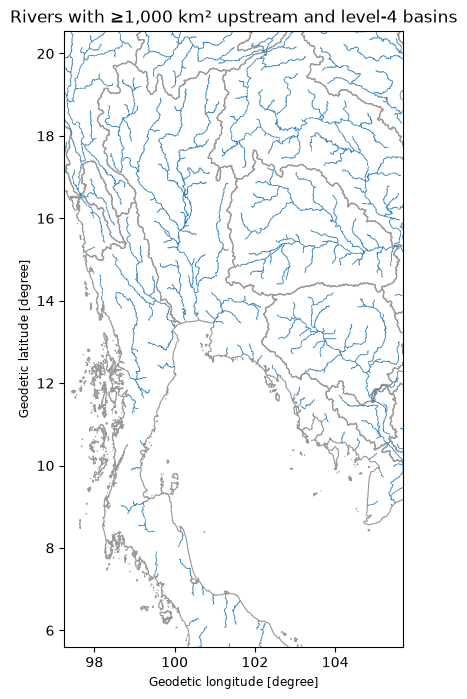

91364 river reaches and 16 level-4 basins in the box


In [22]:
# Quick look: do the rivers and basins actually cover our study area?
import geopandas as gpd
import matplotlib.pyplot as plt

bbox = tuple(ref.rio.bounds())                        # the CHIRPS Thailand box
riv = gpd.read_file(next((RAW_HYDRO / "rivers").rglob("*.shp")), bbox=bbox)
b4 = gpd.read_file(next((RAW_HYDRO / "basins").rglob("*lev04*.shp")), bbox=bbox)

fig, ax = plt.subplots(figsize=(6, 8))
b4.boundary.plot(ax=ax, color="0.6", lw=0.8)
riv[riv.UPLAND_SKM >= 1000].plot(ax=ax, lw=0.6)
ax.set_xlim(bbox[0], bbox[2]); ax.set_ylim(bbox[1], bbox[3])
ax.set_title("Rivers with ≥1,000 km² upstream and level-4 basins")
plt.show()
print(len(riv), "river reaches and", len(b4), "level-4 basins in the box")

**What to check:** the big rivers you know show up (the Chao Phraya through the central plain, the Mun and Chi in the northeast, the Mekong along the border).

## Step 6 · Write the snapshot table

One row per dataset, saved to `data_small/data_snapshot.csv` and printed as a table to paste into the README. **DEM and JRC water** aren't stored as raw files: notebook 03 reads them straight from Microsoft Planetary Computer and saves only the 5 km averages.

In [23]:
in_win = lst[lst.in_window].groupby("year").size()
n_rain = len(list(RAW_CHIRPS.glob("*.tif")))

snapshot = pd.DataFrame([
    {"dataset": "GISTDA flood maps", "source": "disaster.gistda.or.th",
     "detail": f"{len(new)} maps listed; in window {in_win.get(2024, 0)}/{in_win.get(2025, 0)}/{in_win.get(2026, 0)} (2024/25/26)",
     "snapshot_date": TODAY},
    {"dataset": "CHIRPS v3 daily rain", "source": "data.chc.ucsb.edu",
     "detail": f"{n_rain} days; " + ("1 May to 21 Oct" if oct_ready else "1 May to 30 Sep (October not yet released)"),
     "snapshot_date": TODAY},
    {"dataset": "HydroRIVERS / HydroBASINS v1", "source": "hydrosheds.org",
     "detail": "Asia; basin levels 4, 5, 6, 8", "snapshot_date": TODAY},
    {"dataset": "Copernicus DEM 30 m", "source": "Planetary Computer",
     "detail": "read in notebook 03", "snapshot_date": "-"},
    {"dataset": "JRC Global Surface Water", "source": "Planetary Computer",
     "detail": "read in notebook 03", "snapshot_date": "-"},
])
snapshot.to_csv(SMALL_DIR / "data_snapshot.csv", index=False)
try:
    print(snapshot.to_markdown(index=False))      # needs the small 'tabulate' package
except ImportError:
    print(snapshot.to_string(index=False))

                     dataset                source                                           detail snapshot_date
           GISTDA flood maps disaster.gistda.or.th 386 maps listed; in window 57/97/82 (2024/25/26)    2026-11-14
        CHIRPS v3 daily rain     data.chc.ucsb.edu                        522 days; 1 May to 21 Oct    2026-11-14
HydroRIVERS / HydroBASINS v1        hydrosheds.org                    Asia; basin levels 4, 5, 6, 8    2026-11-14
         Copernicus DEM 30 m    Planetary Computer                              read in notebook 03             -
    JRC Global Surface Water    Planetary Computer                              read in notebook 03             -


## Summary

The data are now frozen at today's date, and everything the project needs is on disk, except the DEM and JRC water, which notebook 03 reads directly.

**Save the work** (in a terminal):
```bash
cd ~/thailand-flood-ml
git add -A
git commit -m "Notebook 01: data inventory, GISTDA freeze, HydroSHEDS"
git push
```
Next: `02_build_labels.ipynb`.